In [1]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

# Load the Beans dataset
DATA_DIR = pathlib.Path("../data/beans")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

I0000 00:00:1791707812.158899    2734 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791707823.151593    2734 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791707842.061269    2734 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Train: ../data/beans/train
Validation: ../data/beans/validation
Test: ../data/beans/test


In [4]:
# Define image settings
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# Load training data
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Load validation data
val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Load test data
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.


In [5]:
# Get class names
class_names = train_ds.class_names

print("Classes:")
for index, name in enumerate(class_names):
    print(f"{index}: {name}")

# Verify dataset sizes
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Classes:
0: angular_leaf_spot
1: bean_rust
2: healthy
Training batches: 65
Validation batches: 9
Test batches: 8


In [6]:
# Check actual class distribution
def get_class_counts(dataset, class_names):
    counts = np.zeros(len(class_names), dtype=int)

    for _, labels in dataset:
        labels = labels.numpy()
        for label in labels:
            counts[label] += 1

    return pd.Series(counts, index=class_names)


train_counts = get_class_counts(train_ds, class_names)
val_counts = get_class_counts(val_ds, class_names)
test_counts = get_class_counts(test_ds, class_names)

distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
})

distribution["Total"] = distribution.sum(axis=1)

distribution

W0000 00:00:1791708356.945115    4177 cpu_allocator_impl.cc:82] Allocation of 9633792 exceeds 10% of free system memory.
W0000 00:00:1791708357.065206    4178 cpu_allocator_impl.cc:82] Allocation of 9633792 exceeds 10% of free system memory.
W0000 00:00:1791708357.197156    4179 cpu_allocator_impl.cc:82] Allocation of 9633792 exceeds 10% of free system memory.
W0000 00:00:1791708357.357496    4178 cpu_allocator_impl.cc:82] Allocation of 9633792 exceeds 10% of free system memory.
W0000 00:00:1791708357.525643    4178 cpu_allocator_impl.cc:82] Allocation of 9633792 exceeds 10% of free system memory.


,Train,Validation,Test,Total
angular_leaf_spot,345,44,43,432
bean_rust,348,45,43,436
healthy,341,44,42,427


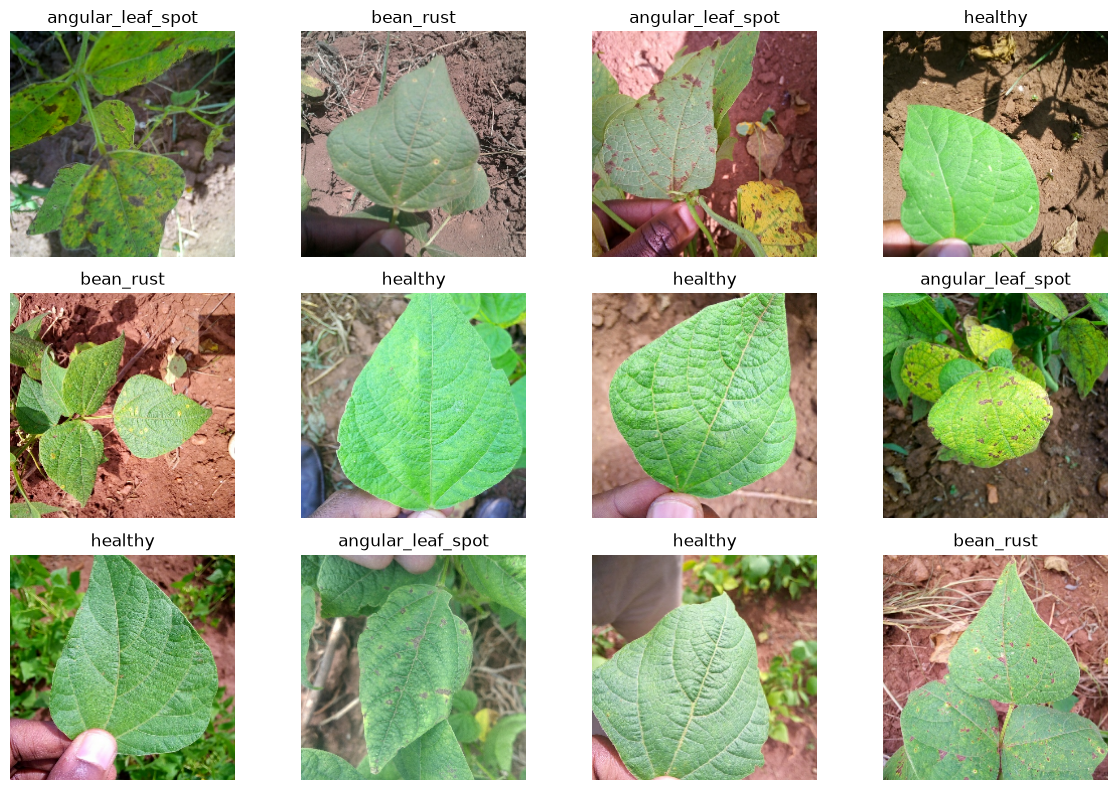

In [8]:
# Visualize sample images
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Data augmentation pipeline

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom(0.10),
    keras.layers.RandomContrast(0.15),
], name="data_augmentation")

Original class: angular_leaf_spot
Image shape: (224, 224, 3)


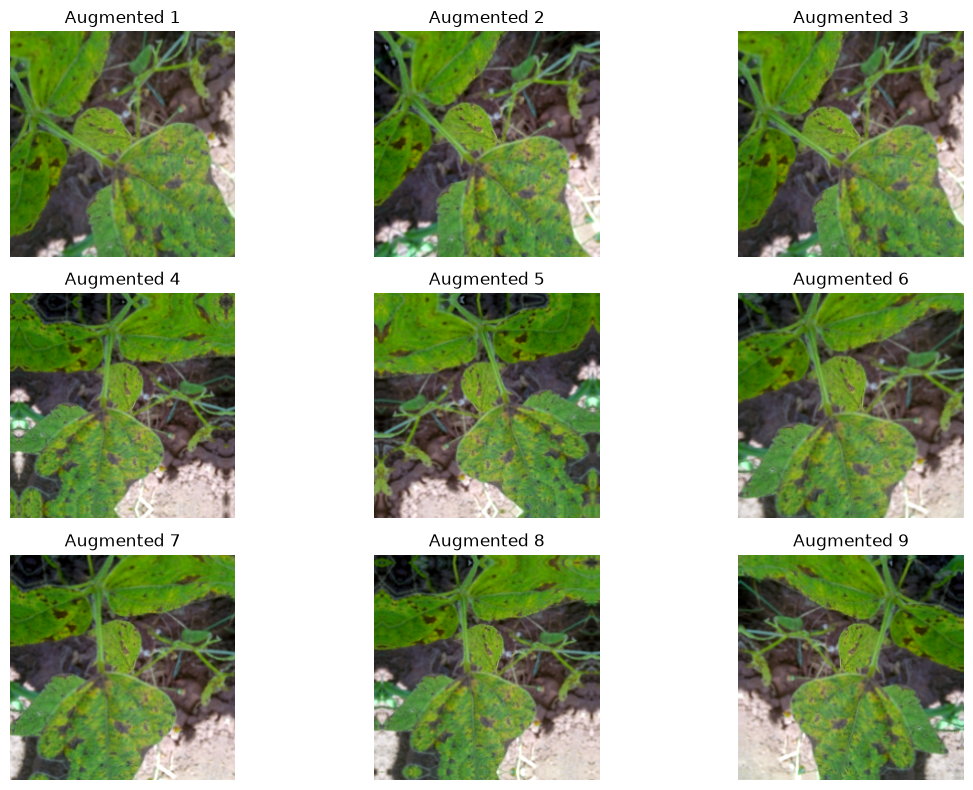

In [9]:
# Get one batch of training images
for images, labels in train_ds.take(1):
    sample_image = images[0]
    sample_label = labels[0]

print("Original class:", class_names[sample_label.numpy()])
print("Image shape:", sample_image.shape)

# Visualize the augmentation
plt.figure(figsize=(12, 8))

for i in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    ax = plt.subplot(3, 3, i + 1)

    plt.imshow(tf.cast(augmented_image, tf.uint8))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
# Build the training pipeline
# Shuffle the training dataset before applying augmentation.

AUTOTUNE = tf.data.AUTOTUNE

train_ds_augmented = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)

train_ds_augmented = train_ds_augmented.prefetch(AUTOTUNE)


val_ds_prepared = val_ds.prefetch(AUTOTUNE)
test_ds_prepared = test_ds.prefetch(AUTOTUNE)

# making sure everything has the expected shape
for images, labels in train_ds_augmented.take(1):
    print("Training batch shape:", images.shape)
    print("Training labels shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Pixel range:", tf.reduce_min(images).numpy(), "to", tf.reduce_max(images).numpy())

Training batch shape: (16, 224, 224, 3)
Training labels shape: (16,)
Image dtype: <dtype: 'float32'>
Pixel range: 0.0 to 255.0


W0000 00:00:1791708412.243915    2734 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 9633856 bytes after encountering the first element of size 9633856 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


In [13]:
# Load EfficientNetB0 with ImageNet pretrained weights

base_model = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("Backbone layers:", len(base_model.layers))
print("Backbone trainable:", base_model.trainable)

Backbone layers: 238
Backbone trainable: False


In [14]:
# Build the classifier
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = keras.layers.GlobalAveragePooling2D()(x)

x = keras.layers.Dense(
    256,
    activation="relu"
)(x)

x = keras.layers.Dropout(0.3)(x)

outputs = keras.layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs
)

# Inspect the model
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,278 (16.70 MB)

 Trainable params: 328,707 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [15]:
# Compile the model for Phase 1 transfer learning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
# Create Phase 1 callbacks
callbacks_phase1 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "models/phase1_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [17]:
# Train the frozen backbone
history_phase1 = model.fit(
    train_ds_augmented,
    validation_data=val_ds_prepared,
    epochs=10,
    callbacks=callbacks_phase1
)

# inspect the history
print("Best validation accuracy:",
      max(history_phase1.history["val_accuracy"]))

print("Best validation loss:",
      min(history_phase1.history["val_loss"]))

Epoch 1/10


/home/walter_2024/IVY/module_5_project/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


65/65 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.7389 - loss: 0.5938 - val_accuracy: 0.8271 - val_loss: 0.3803
Epoch 2/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.8636 - loss: 0.3472 - val_accuracy: 0.8722 - val_loss: 0.2962
Epoch 3/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 120s 2s/step - accuracy: 0.8936 - loss: 0.2923 - val_accuracy: 0.8872 - val_loss: 0.3149
Epoch 4/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.9101 - loss: 0.2370 - val_accuracy: 0.9323 - val_loss: 0.2254
Epoch 5/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.8975 - loss: 0.2373 - val_accuracy: 0.9023 - val_loss: 0.2244
Epoch 6/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.9207 - loss: 0.1941 - val_accuracy: 0.9098 - val_loss: 0.2443
Epoch 7/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.9304 - loss: 0.1891 - val_accuracy: 0.9323 - val_loss: 0.1842
Epoch 8/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.9304 - loss: 0.1673 - val_accuracy: 0.9023 - val_loss: 0.2199
E

In [16]:
# plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_phase1.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_phase1.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Phase 1 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

# plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_phase1.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_phase1.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'history_phase1' is not defined

<Figure size 800x500 with 0 Axes>

In [20]:
# PHASE 2
# Enable fine-tuning of the later EfficientNetB0 layers.

base_model.trainable = True

# Freeze all but the final 20 layers.
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

trainable_backbone_layers = sum(
    layer.trainable for layer in base_model.layers
)

print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone layers:", trainable_backbone_layers)

Total backbone layers: 238
Trainable backbone layers: 15


In [21]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for Phase 2 fine-tuning.")

Model recompiled for Phase 2 fine-tuning.


In [22]:
callbacks_phase2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "models/phase2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_phase2 = model.fit(
    train_ds_augmented,
    validation_data=val_ds_prepared,
    epochs=8,
    callbacks=callbacks_phase2
)

Epoch 1/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 263s 3s/step - accuracy: 0.9507 - loss: 0.1292 - val_accuracy: 0.9248 - val_loss: 0.1853
Epoch 2/8
 1/65 ━━━━━━━━━━━━━━━━━━━━ 45:00 42s/step - accuracy: 0.8750 - loss: 0.1625

W0000 00:00:1791661554.978784   11454 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 9633856 bytes after encountering the first element of size 9633856 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


65/65 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.9584 - loss: 0.1162 - val_accuracy: 0.9098 - val_loss: 0.2172
Epoch 3/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.9516 - loss: 0.1322 - val_accuracy: 0.9248 - val_loss: 0.1986
Epoch 4/8
65/65 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.9594 - loss: 0.1143 - val_accuracy: 0.9098 - val_loss: 0.2247


In [11]:
# Compare the best saved models using validation data.
phase1_model = keras.models.load_model("models/phase1_best.keras")
phase2_model = keras.models.load_model("models/phase2_best.keras")

phase1_loss, phase1_acc = phase1_model.evaluate(
    val_ds_prepared, verbose=0
)
phase2_loss, phase2_acc = phase2_model.evaluate(
    val_ds_prepared, verbose=0
)

print("PHASE I — FROZEN BACKBONE")
print(f"Validation accuracy: {phase1_acc:.2%}")
print(f"Validation loss:     {phase1_loss:.4f}")

print("\nPHASE II — FINE-TUNED BACKBONE")
print(f"Validation accuracy: {phase2_acc:.2%}")
print(f"Validation loss:     {phase2_loss:.4f}")

PHASE I — FROZEN BACKBONE
Validation accuracy: 92.48%
Validation loss:     0.1842

PHASE II — FINE-TUNED BACKBONE
Validation accuracy: 92.48%
Validation loss:     0.1853


In [13]:

"""
Step 2: Final test evaluation

Loads the saved Phase I model and measures performance on
the held-out test dataset. Does not train or fine-tune.
"""

from pathlib import Path
import tensorflow as tf
from tensorflow import keras

MODEL_PATH = Path("models/phase1_best.keras")

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {MODEL_PATH.resolve()}"
    )

# Load the trained model without compiling its training configuration.
final_model = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# Configure the loss and metric for evaluation.
final_model.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate only on the held-out test dataset.
test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9531 - loss: 0.1617

FINAL TEST RESULTS
Test loss:     0.1617
Test accuracy: 95.31%


8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step


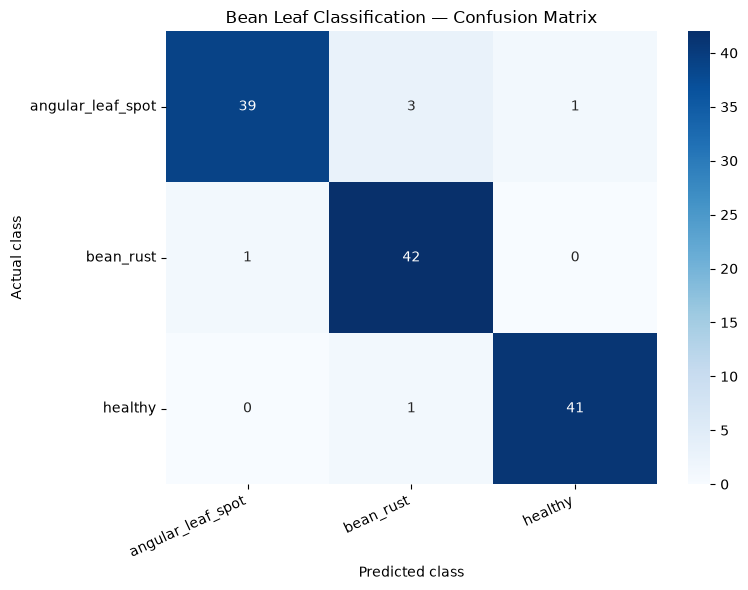


PER-CLASS ACCURACY
            class  correct_predictions  total_test_images  accuracy_percent
angular_leaf_spot                   39                 43         90.697674
        bean_rust                   42                 43         97.674419
          healthy                   41                 42         97.619048

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

angular_leaf_spot       0.97      0.91      0.94        43
        bean_rust       0.91      0.98      0.94        43
          healthy       0.98      0.98      0.98        42

         accuracy                           0.95       128
        macro avg       0.95      0.95      0.95       128
     weighted avg       0.95      0.95      0.95       128


Results saved to: /home/walter_2024/IVY/module_5_project/results


In [14]:

"""
Step 4: Confusion matrix and per-class accuracy

Uses the selected Phase I model and held-out test dataset.
Saves evaluation outputs without retraining.
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Save results in the project root's results folder.
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Collect actual labels from the test dataset.
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Predict the class probabilities for each test image.
probabilities = final_model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Build the confusion matrix in the known class order.
class_ids = list(range(len(class_names)))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids
)

# Plot and save the confusion matrix.
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Bean Leaf Classification — Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Calculate accuracy separately for each actual class.
class_accuracy = []

for i, class_name in enumerate(class_names):
    total = int(cm[i].sum())
    correct = int(cm[i, i])
    accuracy = correct / total if total else 0.0

    class_accuracy.append({
        "class": class_name,
        "correct_predictions": correct,
        "total_test_images": total,
        "accuracy": accuracy
    })

per_class_df = pd.DataFrame(class_accuracy)
per_class_df["accuracy_percent"] = (
    per_class_df["accuracy"] * 100
)

per_class_df.to_csv(
    RESULTS_DIR / "per_class_accuracy.csv",
    index=False
)

print("\nPER-CLASS ACCURACY")
print(
    per_class_df[
        ["class", "correct_predictions",
         "total_test_images", "accuracy_percent"]
    ].to_string(index=False)
)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
))

print(f"\nResults saved to: {RESULTS_DIR.resolve()}")


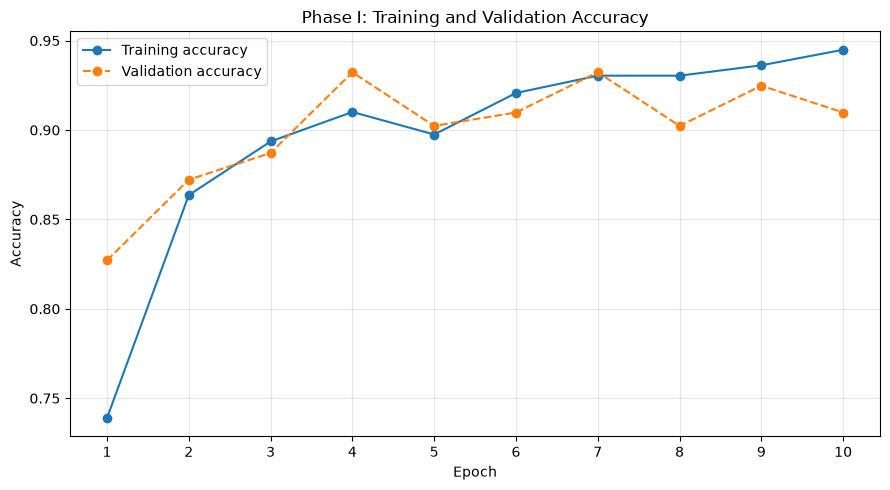

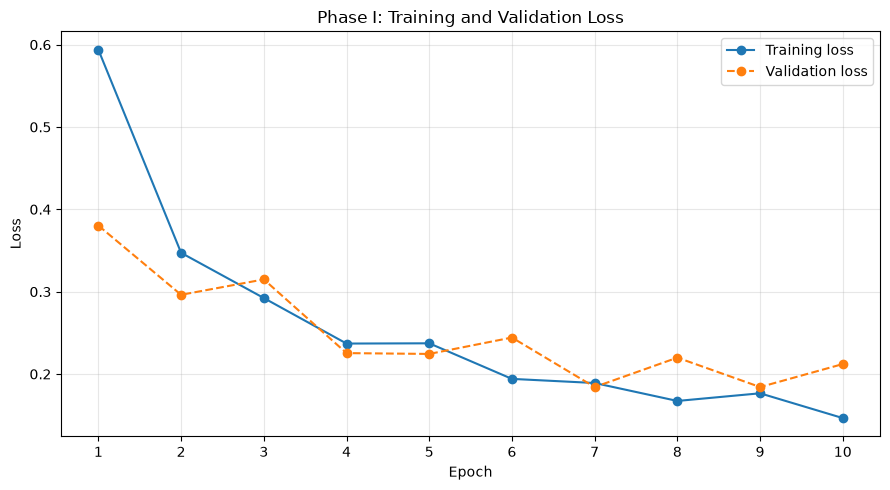

Phase I curves saved to: /home/walter_2024/IVY/module_5_project/results


In [19]:

"""
Reconstruct Phase I training curves from recorded epoch logs.
These are recorded metrics, not a new training run.
"""

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Metrics copied from the Phase I training output.
phase1_history = pd.DataFrame({
    "epoch": list(range(1, 11)),
    "accuracy": [
        0.7389, 0.8636, 0.8936, 0.9101, 0.8975,
        0.9207, 0.9304, 0.9304, 0.9362, 0.9449
    ],
    "loss": [
        0.5938, 0.3472, 0.2923, 0.2370, 0.2373,
        0.1941, 0.1891, 0.1673, 0.1766, 0.1465
    ],
    "val_accuracy": [
        0.8271, 0.8722, 0.8872, 0.9323, 0.9023,
        0.9098, 0.9323, 0.9023, 0.9248, 0.9098
    ],
    "val_loss": [
        0.3803, 0.2962, 0.3149, 0.2254, 0.2244,
        0.2443, 0.1842, 0.2199, 0.1842, 0.2121
    ]
})

# Preserve the reconstructed metrics for future use.
phase1_history.to_csv(
    RESULTS_DIR / "phase1_history_reconstructed.csv",
    index=False
)

# Accuracy curves.
plt.figure(figsize=(9, 5))
plt.plot(
    phase1_history["epoch"],
    phase1_history["accuracy"],
    marker="o",
    label="Training accuracy"
)
plt.plot(
    phase1_history["epoch"],
    phase1_history["val_accuracy"],
    marker="o",
    linestyle="--",
    label="Validation accuracy"
)
plt.title("Phase I: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(phase1_history["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "phase1_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Loss curves.
plt.figure(figsize=(9, 5))
plt.plot(
    phase1_history["epoch"],
    phase1_history["loss"],
    marker="o",
    label="Training loss"
)
plt.plot(
    phase1_history["epoch"],
    phase1_history["val_loss"],
    marker="o",
    linestyle="--",
    label="Validation loss"
)
plt.title("Phase I: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(phase1_history["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "phase1_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Phase I curves saved to:", RESULTS_DIR.resolve())


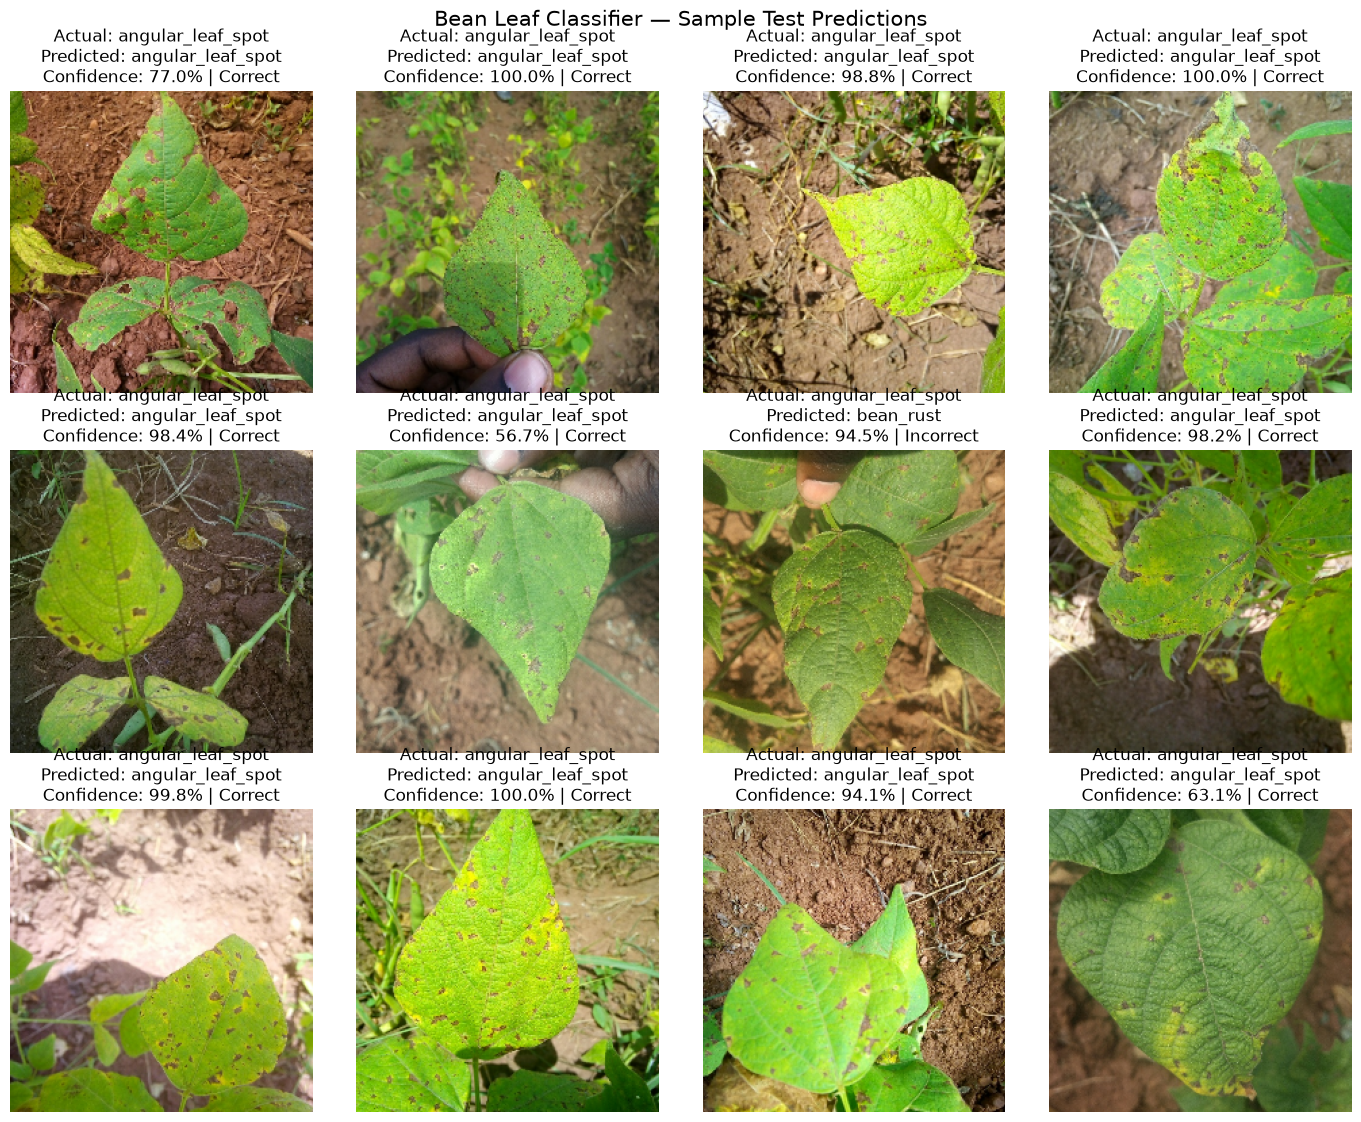

Sample prediction visualization saved to: /home/walter_2024/IVY/module_5_project/results/sample_predictions.png


In [20]:

"""
Step 6: Visualize sample test predictions.

Displays actual and predicted classes with confidence scores.
Saves the visualization without retraining the model.
"""

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Take one batch from the test dataset.
images, labels = next(iter(test_ds))

# Predict class probabilities for this batch.
probabilities = final_model.predict(images, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)
confidences = np.max(probabilities, axis=1)

# Display up to 12 examples.
num_images = min(12, len(images))
columns = 4
rows = int(np.ceil(num_images / columns))

fig, axes = plt.subplots(
    rows, columns,
    figsize=(14, 3.8 * rows)
)
axes = np.array(axes).reshape(-1)

for i in range(num_images):
    actual = int(labels[i].numpy())
    predicted = int(predicted_labels[i])

    axes[i].imshow(
        np.clip(images[i].numpy() / 255.0, 0, 1)
    )

    status = "Correct" if actual == predicted else "Incorrect"

    axes[i].set_title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"Confidence: {confidences[i]:.1%} | {status}"
    )
    axes[i].axis("off")

# Hide unused subplot positions.
for i in range(num_images, len(axes)):
    axes[i].axis("off")

fig.suptitle(
    "Bean Leaf Classifier — Sample Test Predictions",
    fontsize=15
)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "sample_predictions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(
    "Sample prediction visualization saved to:",
    (RESULTS_DIR / "sample_predictions.png").resolve()
)
